# College Majors 2026: Model 1, Ridge Regression
## Predicting 4-year earnings of bachelor's programs

**Task (regression):** predict `target_log_earnings_4yr`, the log of a program's median earnings 4 years after completion.

**Model 1 — Ridge regression:** the linear model from class with an L2 penalty. It's a strong, interpretable starting
point, and its coefficients show the direction and size of each feature's effect.

It uses the **preprocessing pipeline** from the data-prep notebook and the **grouped train/test split**. Models 2 and 3
can reuse the same `make_preprocess()`, `cv` and `evaluate()` code in this notebook, so the comparison stays fair.

> **To run:** put `bachelors_model_ready.csv` (made by the data-prep notebook) next to this notebook, then *Run All*.
> It runs in under a minute.

## 0. Setup

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import GroupKFold, GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50, "display.width", 200)
%matplotlib inline

RANDOM_STATE = 42
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID, BG = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW = PALETTE[:4]
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": BG, "axes.facecolor": BG,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "xtick.color": INK2, "ytick.color": INK2, "font.size": 10,
})
def show(fig, name):
    fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, name), bbox_inches="tight"); plt.show()

## 1. Load the model-ready data and define features

In [2]:
df = pd.read_csv("bachelors_model_ready.csv", dtype={"opeid6": str, "cip_code_4digit": str})

NUMERIC = [
    "log_awards_avg", "is_main_campus", "outcomes_shared_across_campuses",
    "log_enrollment", "institution_tuition_in_state_usd", "tuition_out_minus_in",
    "institution_admission_rate", "admission_rate_missing", "institution_avg_sat", "sat_missing",
    "institution_is_hbcu", "institution_latitude", "institution_longitude",
    "national_median_earnings_4yr_usd",
    "linked_occupations_count", "occupation_median_wage_2024_usd", "occupation_growth_pct_2024_34",
    "occupation_growth_pct_max", "log_occ_employment",
    "occupations_using_ai_software", "ai_software_occupation_share", "expert_system_occupation_share",
    "ai_tools_max_per_occupation", "hot_technologies_mean_per_occupation", "any_ai_occupation",
]
CATEGORICAL = ["institution_control", "institution_region", "cip_family_title",
               "online", "selectivity", "occupation_typical_entry_education"]
FEATURES = NUMERIC + CATEGORICAL
TARGET = "target_log_earnings_4yr"
GROUP = "opeid6"

train = df[df.split == "train"].reset_index(drop=True)
test = df[df.split == "test"].reset_index(drop=True)
X_train, y_train, g_train = train[FEATURES], train[TARGET], train[GROUP]
X_test, y_test = test[FEATURES], test[TARGET]
print(f"Train: {X_train.shape}  |  Test: {X_test.shape}  |  Features: {len(FEATURES)}")

Train: (19932, 31)  |  Test: (5351, 31)  |  Features: 31


## 2. Shared preprocessing and cross-validation

- **Preprocessing** (inside every model's pipeline, fit on training folds only): median-impute and scale numbers; one-hot encode categories.
- **Cross-validation:** `GroupKFold(5)` grouped by institution, so a school is never in both the fitting and validation part of a fold.
  This matches how the test set was built.
- **Tuning metric:** R² on log earnings. Final results are also reported **in dollars**.

In [3]:
def make_preprocess():
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), NUMERIC),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=30, sparse_output=False), CATEGORICAL),
    ])

cv = GroupKFold(n_splits=5)
results = {}          # test-set results for each model
cv_scores = {}        # best cross-validated R² for each model

## 3. Baseline: predict the field's national median

The simplest possible prediction, needing no model. Every model must beat it to be worth using.

In [4]:
def evaluate(name, pred_log):
    """Score predictions on the test set, both on log scale and in dollars."""
    actual = np.exp(y_test); pred = np.exp(pred_log)
    results[name] = {
        "R² (log)": r2_score(y_test, pred_log),
        "RMSE ($)": np.sqrt(mean_squared_error(actual, pred)),
        "MAE ($)": mean_absolute_error(actual, pred),
        "Median abs. % error": np.median(np.abs(pred - actual) / actual) * 100,
    }
    return pd.Series(results[name]).round(3)

base_pred = np.log(test["national_median_earnings_4yr_usd"])
evaluate("Baseline (national field median)", base_pred)

R² (log)                   0.566
RMSE ($)               12624.187
MAE ($)                 8760.366
Median abs. % error       10.413
dtype: float64

## 4. Model 1: Ridge regression

**How it works:** linear regression with an L2 penalty, `alpha`, that shrinks coefficients toward zero.
Larger `alpha` = simpler model, which helps when features are correlated (e.g. the AI-exposure measures).

**Tuning:** grid search over 13 values of `alpha` from 0.001 to 1,000 (log-spaced), because the right amount of shrinkage
can differ by orders of magnitude.

In [5]:
ridge = Pipeline([("prep", make_preprocess()), ("model", Ridge())])
ridge_grid = {"model__alpha": np.logspace(-3, 3, 13)}

t = time.time()
ridge_search = GridSearchCV(ridge, ridge_grid, cv=cv, scoring="r2", n_jobs=-1, return_train_score=True)
ridge_search.fit(X_train, y_train, groups=g_train)
print(f"Done in {time.time() - t:.0f}s | best alpha = {ridge_search.best_params_['model__alpha']:.3g} "
      f"| CV R² = {ridge_search.best_score_:.3f}")
cv_scores["Ridge regression"] = ridge_search.best_score_

Done in 4s | best alpha = 3.16 | CV R² = 0.753


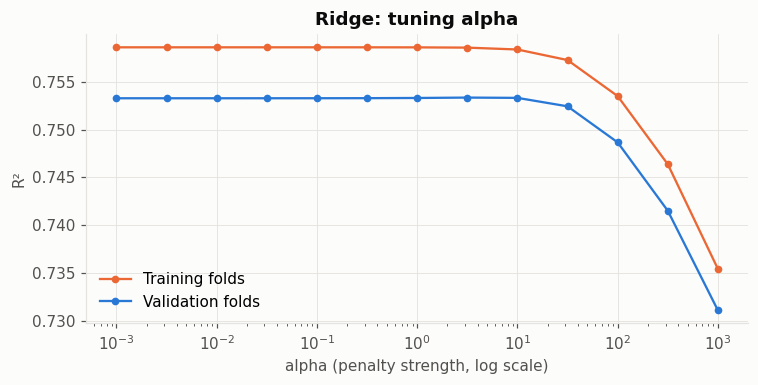

R² (log)                   0.744
RMSE ($)               10005.070
MAE ($)                 7029.768
Median abs. % error        8.583
dtype: float64

In [6]:
cvr = pd.DataFrame(ridge_search.cv_results_)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(cvr.param_model__alpha.astype(float), cvr.mean_train_score, color=ORANGE, marker="o", markersize=4, label="Training folds")
ax.plot(cvr.param_model__alpha.astype(float), cvr.mean_test_score, color=BLUE, marker="o", markersize=4, label="Validation folds")
ax.set_xscale("log"); ax.set(xlabel="alpha (penalty strength, log scale)", ylabel="R²", title="Ridge: tuning alpha")
ax.legend(frameon=False)
show(fig, "m1_ridge_tuning.png")
evaluate("Ridge regression", ridge_search.predict(X_test))

The curve is flat over small `alpha` values and drops only when the penalty becomes very strong. The linear model isn't
overfitting (training and validation scores are close), so its limit is **bias**: it can only fit straight-line effects.

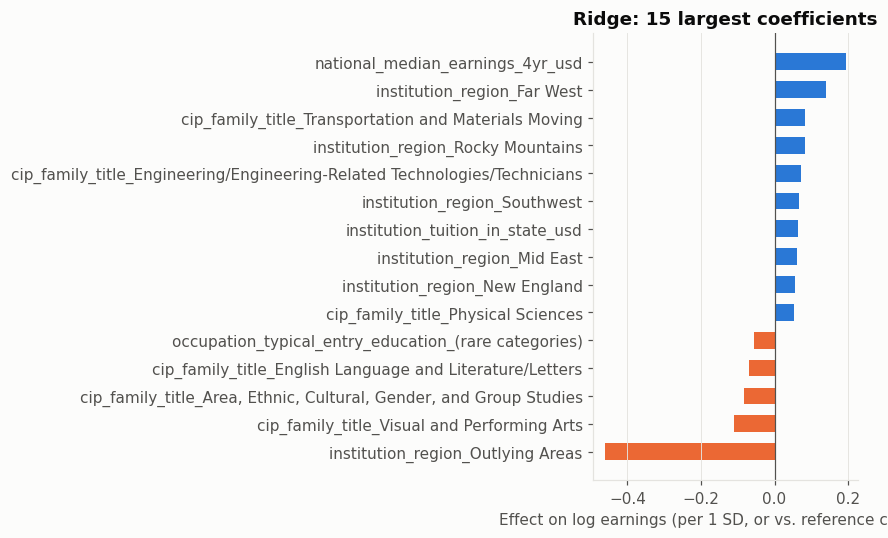

In [7]:
# Largest coefficients (features are standardised, so sizes are comparable)
best_ridge = ridge_search.best_estimator_
names = best_ridge.named_steps["prep"].get_feature_names_out()
coef = pd.Series(best_ridge.named_steps["model"].coef_, index=names)
coef.index = (coef.index.str.replace("num__", "").str.replace("cat__", "")
              .str.replace("_infrequent_sklearn", "_(rare categories)"))
top = coef.reindex(coef.abs().sort_values(ascending=False).index[:15]).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values, color=[BLUE if v > 0 else ORANGE for v in top.values], height=0.6)
ax.axvline(0, color=INK2, linewidth=0.8)
ax.set(title="Ridge: 15 largest coefficients", xlabel="Effect on log earnings (per 1 SD, or vs. reference category)")
ax.grid(axis="y", visible=False)
show(fig, "m1_ridge_coefficients.png")

**How to read this:** a coefficient of 0.05 on log earnings ≈ **+5% earnings**. Blue = higher earnings, orange = lower.
For numeric features the effect is per 1 standard deviation. For categories it's relative to the other categories, since all
categories are kept (one-hot without dropping one), so compare categories with each other rather than reading each alone.

- **National field median** has the largest positive effect: the field sets the base pay level.
- **Region:** programs in the Far West, Rocky Mountains, Southwest, Mid East and New England earn more than similar programs elsewhere,
  largely reflecting regional wage and cost-of-living levels. *Outlying Areas* (Puerto Rico, Guam and other territories) earn substantially less (coefficient ≈ −0.45).
- **Field family** adds to the national benchmark: arts, humanities and area studies earn less, engineering technology and physical sciences more.
- **In-state tuition** is positive: pricier schools (often selective private ones) have higher-earning graduates.

## 5. Results: Ridge vs. baseline

**Metrics (use the same ones for every model later):**
- **R² (log scale):** share of variation in log earnings explained (1 = perfect). Matches what the models were trained on.
- **RMSE ($):** typical error in dollars; punishes big misses more.
- **MAE ($):** average absolute error in dollars; easiest to explain ("off by $X on average").
- **Median abs. % error:** typical error as a percentage of the program's actual earnings.

**CV R²** is from tuning on the training data; the other columns are from the untouched **test set** (360 institutions the model has never seen).

In [8]:
comp = pd.DataFrame(results).T
comp.insert(0, "CV R² (train)", pd.Series(cv_scores))
comp_fmt = comp.copy()
for c in ["RMSE ($)", "MAE ($)"]: comp_fmt[c] = comp[c].map("${:,.0f}".format)
comp_fmt["Median abs. % error"] = comp["Median abs. % error"].map("{:.1f}%".format)
for c in ["CV R² (train)", "R² (log)"]: comp_fmt[c] = comp[c].map(lambda v: "—" if pd.isna(v) else f"{v:.3f}")
comp_fmt

,CV R² (train),R² (log),RMSE ($),MAE ($),Median abs. % error
Baseline (national field median),—,0.566,"$12,624","$8,760",10.4%
Ridge regression,0.753,0.744,"$10,005","$7,030",8.6%


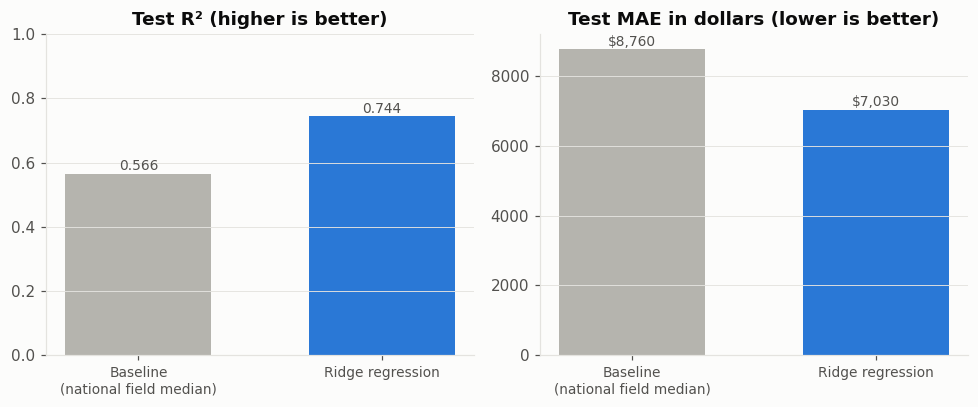

In [9]:
colors = ["#b5b4ae", BLUE]
short = ["Baseline\n(national field median)", "Ridge regression"]

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
vals = comp["R² (log)"].values
axes[0].bar(short, vals, color=colors, width=0.6)
for x, v in enumerate(vals): axes[0].text(x, v + 0.01, f"{v:.3f}", ha="center", fontsize=9, color=INK2)
axes[0].set(title="Test R² (higher is better)", ylim=(0, 1)); axes[0].grid(axis="x", visible=False)
vals = comp["MAE ($)"].values
axes[1].bar(short, vals, color=colors, width=0.6)
for x, v in enumerate(vals): axes[1].text(x, v + 100, f"${v:,.0f}", ha="center", fontsize=9, color=INK2)
axes[1].set(title="Test MAE in dollars (lower is better)"); axes[1].grid(axis="x", visible=False)
for a in axes: a.tick_params(axis="x", labelsize=9)
show(fig, "m1_ridge_vs_baseline.png")

### 5.1 Predicted vs. actual, and the size of the errors

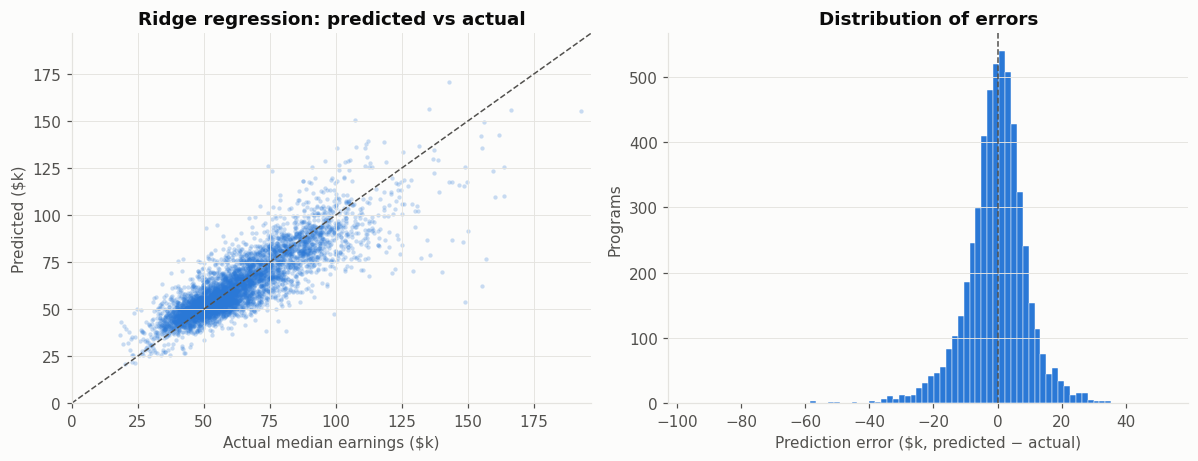

Programs predicted within ±10%: 56%
Programs predicted within ±20%: 85%


In [10]:
best_name, best = "Ridge regression", ridge_search
pred = np.exp(best.predict(X_test)); actual = np.exp(y_test)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
axes[0].scatter(actual / 1000, pred / 1000, s=8, alpha=0.25, color=BLUE, linewidths=0)
lim = [0, max(actual.max(), pred.max()) / 1000 * 1.02]
axes[0].plot(lim, lim, color=INK2, linestyle="--", linewidth=1)
axes[0].set(xlim=lim, ylim=lim, xlabel="Actual median earnings ($k)", ylabel="Predicted ($k)",
            title=f"{best_name}: predicted vs actual")
err = (pred - actual) / 1000
axes[1].hist(err, bins=80, color=BLUE, edgecolor=BG, linewidth=0.3)
axes[1].axvline(0, color=INK2, linestyle="--", linewidth=1)
axes[1].set(xlabel="Prediction error ($k, predicted − actual)", ylabel="Programs", title="Distribution of errors")
axes[1].grid(axis="x", visible=False)
show(fig, "m1_ridge_pred_vs_actual.png")
print(f"Programs predicted within ±10%: {(np.abs(pred - actual) / actual <= 0.10).mean():.0%}")
print(f"Programs predicted within ±20%: {(np.abs(pred - actual) / actual <= 0.20).mean():.0%}")

Points cluster around the diagonal. The largest misses are the very high earners (top CS/math programs at elite schools),
which the model **under-predicts**: there are few such programs to learn from, and predictions on the log scale pull extremes toward the middle.

### 5.2 Which features matter most? (permutation importance)

**Permutation importance:** shuffle one feature's values in the test set and measure how much R² drops.
A big drop means the model relies on that feature. It works the same way for any model, so you can compare it directly with Models 2 and 3 later.

Computed in 0s


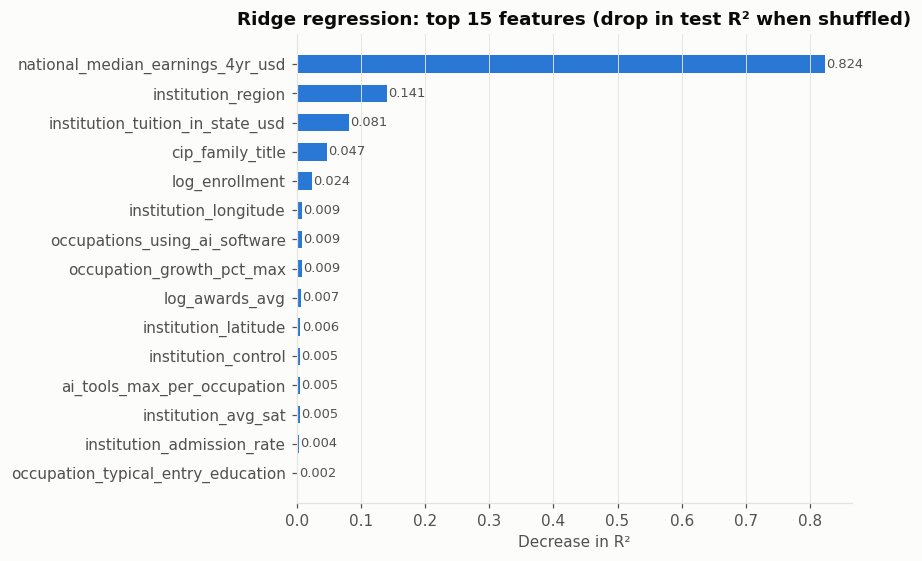

In [11]:
t = time.time()
pi = permutation_importance(best, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE, scoring="r2", n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False)
print(f"Computed in {time.time() - t:.0f}s")

top = imp.head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.barh(top.index, top.values, color=BLUE, height=0.6)
for i, v in enumerate(top.values): ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8.5, color=INK2)
ax.set(title=f"{best_name}: top 15 features (drop in test R² when shuffled)", xlabel="Decrease in R²")
ax.grid(axis="y", visible=False)
show(fig, "m1_ridge_permutation_importance.png")

## 6. Summary

In [12]:
b = comp.loc["Baseline (national field median)"]; m = comp.loc[best_name]
print("Ridge regression on the test set")
print(f"  Test R² {m['R² (log)']:.3f} vs baseline {b['R² (log)']:.3f}  "
      f"(+{m['R² (log)'] - b['R² (log)']:.3f})")
print(f"  MAE ${m['MAE ($)']:,.0f} vs baseline ${b['MAE ($)']:,.0f}  "
      f"({(1 - m['MAE ($)'] / b['MAE ($)']):.0%} smaller)")
print(f"  Top 5 features: {', '.join(imp.index[:5])}")

Ridge regression on the test set
  Test R² 0.744 vs baseline 0.566  (+0.178)
  MAE $7,030 vs baseline $8,760  (20% smaller)
  Top 5 features: national_median_earnings_4yr_usd, institution_region, institution_tuition_in_state_usd, cip_family_title, log_enrollment


### Takeaways
- **Ridge clearly beats the baseline:** test R² rises from **0.566 to 0.744**, and the average error (MAE) falls from **$8,760 to $7,030** (20% smaller).
  So institution, region and labor-market features add real information beyond "which field is it".
- **It generalizes:** CV R² (0.753) and test R² (0.744) are almost identical, and training vs. validation scores are close.
  The model is not overfitting, and the results hold for **institutions it has never seen**.
- **Typical accuracy:** the median program is predicted within **8.6%** of its actual earnings; 56% are within ±10% and 85% within ±20%.
- **Where it struggles:** it **under-predicts the highest earners** (top CS/math programs at elite schools, $150k+). A linear model
  can't capture the extra premium that comes from combining a high-paying field with a highly selective school.
- **Most important features:** the field's national median dominates, followed by region, in-state tuition, field family and school size.
  SAT and admission rate add little on their own because tuition and region already carry much of that information.

**Next step:** Models 2 and 3 (random forest and gradient boosting) can capture nonlinear effects and interactions,
which should help with the high earners. They can reuse `make_preprocess()`, `cv` and `evaluate()` from this notebook unchanged.